# 5. Deux approches explorées puis écartées

**Prédiction de la qualité des soudures**

Marie Gozlan, Jules Mortreux, Grégoire Pascual, Pétronille Tard

---

## Pourquoi un notebook sur ce qui n'a pas été retenu

Ce notebook traite deux approches que nous avons explorées complètement et que
nous n'avons **pas** retenues pour la prédiction.

**La classification**, qui consiste à prédire une catégorie de qualité plutôt
qu'un score continu.

**La sélection de variables**, qui consiste à chercher le meilleur
sous-ensemble de variables d'entrée plutôt que de les garder toutes.

Les présenter plutôt que de les taire répond à trois raisons.

**Un résultat négatif obtenu après un travail complet est une conclusion ; le
même résultat obtenu après un essai bâclé est un aveu.** Nous avions d'abord
testé la classification de façon sommaire, et notre propre notebook
d'exploration avait écrit noir sur blanc la réserve qui en découlait : les
classifieurs n'avaient pas été réglés, donc la comparaison ne valait rien. Une
réserve inscrite dans le dépôt et jamais levée se retourne contre son auteur.

**Les deux approches couvrent des notions du programme** qui n'apparaissent
nulle part ailleurs dans notre travail : les mesures d'impureté d'un arbre, le
traitement du déséquilibre de classes, et la sélection pas à pas avec ses
critères.

**Et la seconde est utile, même si elle n'améliore rien.** La sélection de
variables ne gagne rien en prédiction, mais elle désigne les leviers d'action
avec un degré de confiance mesurable, ce dont le notebook 7 a besoin pour
formuler des recommandations.

## Ce que ce notebook conclut

**La classification fonctionne et n'est pas retenue**, parce qu'à performance
comparable le seuillage du modèle de régression du notebook 4 produit deux fois
moins d'erreurs graves, et qu'il ne coûte rien de plus.

**La sélection de variables n'améliore pas la prédiction**, mais elle établit
que deux variables suffisent à capter l'essentiel de ce qu'un modèle linéaire
peut extraire, et lesquelles.

In [1]:
from pathlib import Path
from collections import Counter
import json
import sys
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import (HistGradientBoostingClassifier,
                              HistGradientBoostingRegressor,
                              RandomForestClassifier)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LassoCV, LinearRegression, LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
                             confusion_matrix, f1_score, mean_squared_error)
from sklearn.model_selection import GroupKFold, ParameterGrid
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore", category=FutureWarning)

ROOT = Path.cwd()
while not (ROOT / "data" / "raw").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
OUT = ROOT / "outputs" / "rendu5"
OUT.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(ROOT / "src"))
import export_processed as nettoyage

GRAINE = 42
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True,
                     "grid.alpha": 0.3, "font.size": 10})

CATEGORIES = ["AC_DC", "Electrode_pol", "WeldType"]
RESISTANCE = ["YieldStrength_MPa", "UTS_MPa"]
DUCTILITE = ["Elongation_pct", "ReductionArea_pct"]
PROPRIETES = RESISTANCE + DUCTILITE

donnees = pd.read_csv(ROOT / "outputs/rendu2/dataset_qualite.csv",
                      index_col="row_id",
                      dtype={c: str for c in CATEGORIES + ["WeldID", "partition"]},
                      keep_default_na=False, na_values=[""],
                      float_precision="round_trip")
VARIABLES = nettoyage.COMPOSITION + nettoyage.PROCESS
dev = donnees["partition"] == "developpement"
X = donnees.loc[dev, VARIABLES]
Y = donnees.loc[dev, PROPRIETES]
score = donnees.loc[dev, "score_qualite"]
groupes = donnees.loc[dev, "groupe"]

print(f"Développement : {len(X)} lignes, {groupes.nunique()} soudures.")
print("L'ensemble de test n'est pas utilisé dans ce notebook : il ne tranche")
print("aucun choix final, et le notebook 4 l'a déjà consulté une fois.")

Développement : 527 lignes, 376 soudures.
L'ensemble de test n'est pas utilisé dans ce notebook : il ne tranche
aucun choix final, et le notebook 4 l'a déjà consulté une fois.


In [2]:
def poids_par_soudure(g):
    """Chaque soudure pèse un, réparti sur ses lignes."""
    return (1 / g.map(g.value_counts())).to_numpy()


def reference_rangs(valeurs, g):
    """Table de conversion valeur vers rang, pondérée, en mi-rang."""
    poids = 1 / g.map(g.value_counts())
    table = pd.DataFrame({"valeur": valeurs, "poids": poids}).dropna()
    masse = table.groupby("valeur")["poids"].sum()
    return (masse.index.to_numpy(),
            ((masse.cumsum() - masse / 2) / masse.sum()).to_numpy())


def calculer_score(mesures_reference, groupes_reference, mesures_a_noter):
    """Recalcule la cible du notebook 2 avec les rangs de la référence."""
    rangs = pd.DataFrame(index=mesures_a_noter.index)
    for mesure in PROPRIETES:
        grille, grille_rangs = reference_rangs(mesures_reference[mesure],
                                               groupes_reference)
        rangs[mesure] = np.interp(mesures_a_noter[mesure], grille, grille_rangs)
    return pd.Series(np.sqrt(rangs[RESISTANCE].mean(axis=1)
                             * rangs[DUCTILITE].mean(axis=1)),
                     index=mesures_a_noter.index)


def creer_preparation(X_apprentissage, normaliser=False, seuil=0.25):
    """Préparation du notebook 3."""
    taux = X_apprentissage.notna().mean()
    retenues = taux[taux >= seuil].index.tolist()
    numeriques = [c for c in retenues if c not in CATEGORIES]
    categorielles = [c for c in retenues if c in CATEGORIES]
    etapes = [("mediane", SimpleImputer(strategy="median"))]
    if normaliser:
        etapes.append(("echelle", StandardScaler()))
    return ColumnTransformer([
        ("nombres", Pipeline(etapes), numeriques),
        ("categories", Pipeline([
            ("manquants", SimpleImputer(strategy="constant",
                                        fill_value="manquant")),
            ("encodage", OneHotEncoder(drop="first", handle_unknown="ignore",
                                       sparse_output=False)),
        ]), categorielles),
    ])


PLIS = []
for train, validation in GroupKFold(n_splits=5).split(X, groups=groupes):
    ids_train, ids_val = X.index[train], X.index[validation]
    assert set(groupes.loc[ids_train]).isdisjoint(set(groupes.loc[ids_val]))
    PLIS.append((ids_train, ids_val))
print(f"5 plis par groupes, tailles de validation {[len(v) for _, v in PLIS]}.")

5 plis par groupes, tailles de validation [106, 106, 105, 105, 105].


## 1. La classification : pourquoi se poser la question

Nos modèles prédisent un score continu. Trois raisons rendent l'alternative
catégorielle légitime.

**Une raison d'usage.** Dans un atelier, la décision n'est pas un nombre, c'est
un verdict : cette soudure est acceptée, ou elle doit être reprise. Une sortie
catégorielle correspond mieux à cet usage qu'un score à trois décimales.

**Une raison statistique.** Notre cible est construite à partir de mesures
expérimentales incertaines. Prétendre distinguer un score de 0,61 d'un score de
0,63 est probablement illusoire ; distinguer un tiers inférieur d'un tiers
supérieur est beaucoup plus robuste.

**Une raison de programme.** Le cours couvre les deux familles, régression et
classification, et la classification mobilise des notions qui n'existent pas en
régression.

### 1.1 Deux découpages, pour deux questions

**Trois classes aux tiers, pour décrire.** On coupe la distribution du score en
trois parts égales. Ce découpage ne correspond à aucune exigence industrielle,
notre score étant un rang sans unité, mais il permet de dire d'une soudure
qu'elle appartient au tiers supérieur du corpus. Les classes étant équilibrées,
une réponse au hasard donne environ 33 %, et l'exactitude est donc directement
interprétable.

**Deux classes à un seuil de rebut, pour décider.** On définit une classe
`à reprendre` correspondant au quart inférieur, et `acceptable` pour le reste.
Pourquoi le quart ? Aucune norme ne le dit, donc le choix est conventionnel et
nous l'assumons comme tel : assez large pour que la classe de rebut soit
apprenable, assez étroit pour représenter un rebut plausible.

**Ce second découpage introduit un déséquilibre de classes**, et avec lui deux
difficultés que la section 4 traite.

In [3]:
CLASSES_3 = ["faible", "moyen", "élevé"]
CLASSES_2 = ["à reprendre", "acceptable"]
DECOUPAGES = {
    "trois classes": (CLASSES_3, [-0.01, 1 / 3, 2 / 3, 1.01]),
    "deux classes": (CLASSES_2, [-0.01, 0.25, 1.01]),
}


def discretiser(valeurs, reference, decoupage):
    """Convertit un score en classes, avec les seuils du découpage demandé.

    Le score est d'abord converti en rang pondéré à l'aide de la référence
    fournie, qui provient toujours du seul apprentissage du pli.
    """
    etiquettes, bornes = DECOUPAGES[decoupage]
    rang = np.interp(valeurs, *reference)
    return pd.cut(pd.Series(rang, index=valeurs.index), bins=bornes,
                  labels=etiquettes, ordered=True)


reference_globale = reference_rangs(score, groupes)
controles = []
for decoupage, (etiquettes, _) in DECOUPAGES.items():
    classes = discretiser(score, reference_globale, decoupage)
    for etiquette in etiquettes:
        masque = classes == etiquette
        controles.append({
            "découpage": decoupage, "classe": etiquette,
            "lignes": int(masque.sum()), "part": masque.mean(),
            "soudures": groupes[masque].nunique(),
            "score minimum": score[masque].min(),
            "score maximum": score[masque].max()})
display(pd.DataFrame(controles).set_index(["découpage", "classe"]).round(3))

lignes   part  soudures  score minimum  \
découpage     classe                                                
trois classes faible          181  0.343       145          0.042   
              moyen           160  0.304       147          0.376   
              élevé           186  0.353       144          0.493   
deux classes  à reprendre     139  0.264       107          0.042   
              acceptable      388  0.736       295          0.339   

                           score maximum  
découpage     classe                      
trois classes faible               0.376  
              moyen                0.493  
              élevé                0.720  
deux classes  à reprendre          0.339  
              acceptable           0.720

### 1.2 Les métriques, et celle qui décide

Quatre indicateurs, et il faut savoir lequel tranche.

L'**exactitude** est la part de soudures bien classées. L'**exactitude
équilibrée** est la moyenne des taux de bonne détection classe par classe, donc
elle reste interprétable même quand les classes sont déséquilibrées. Le **F1
macro** combine, pour chaque classe, la justesse des annonces et la capacité à
ne pas en manquer, puis traite les classes à égalité.

Et les **erreurs graves**, que nous ajoutons. Nos classes sont **ordonnées** :
confondre `moyen` et `élevé` est mineur, la frontière entre elles étant
conventionnelle. Confondre `faible` et `élevé` est tout autre chose. **Aucune
métrique standard de classification ne tient compte de cet ordre**, d'où cet
indicateur.

**Une précision importante : cet indicateur perd son sens avec deux classes.**
Il n'y a alors plus de classe voisine ni de classe extrême, donc toute erreur
est une confusion entre les deux seules classes existantes, et l'indicateur
dégénère en un simple compte total d'erreurs. C'est pourquoi la section 4
introduit deux autres colonnes pour le découpage binaire.

**Le critère de sélection déclaré d'avance est le F1 macro**, parce qu'il traite
les classes à égalité et reste valable pour les deux découpages. Les erreurs
graves servent ensuite à arbitrer entre modèles de F1 voisins.

In [4]:
def evaluer_classifieur(modele, preparation=None, decoupage="trois classes",
                        avec_poids=True):
    """Valide un classifieur sur les cinq plis et cumule la confusion.

    Les classes sont converties en codes entiers ordonnés : certaines
    implémentations n'acceptent pas des étiquettes en texte. L'ordre est
    conservé, zéro étant la classe la plus basse.
    """
    etiquettes = DECOUPAGES[decoupage][0]
    codes = list(range(len(etiquettes)))
    scores = []
    matrice = np.zeros((len(etiquettes), len(etiquettes)), dtype=int)

    for ids_train, ids_val in PLIS:
        reference = reference_rangs(score.loc[ids_train], groupes.loc[ids_train])
        y = discretiser(score, reference, decoupage).cat.codes
        poids_train = poids_par_soudure(groupes.loc[ids_train])
        poids_val = poids_par_soudure(groupes.loc[ids_val])

        pipeline = Pipeline([
            ("preparation", creer_preparation(X.loc[ids_train],
                                              **(preparation or {}))),
            ("modele", clone(modele))])
        if avec_poids:
            pipeline.fit(X.loc[ids_train], y.loc[ids_train],
                         modele__sample_weight=poids_train)
        else:
            pipeline.fit(X.loc[ids_train], y.loc[ids_train])

        prediction = pipeline.predict(X.loc[ids_val])
        verite = y.loc[ids_val]
        scores.append([
            accuracy_score(verite, prediction, sample_weight=poids_val),
            balanced_accuracy_score(verite, prediction, sample_weight=poids_val),
            f1_score(verite, prediction, average="macro", labels=codes,
                     sample_weight=poids_val)])
        matrice += confusion_matrix(verite, prediction, labels=codes)

    tableau = np.array(scores)
    graves = int(matrice[0, -1] + matrice[-1, 0])
    return {"exactitude": tableau[:, 0].mean(),
            "exactitude équilibrée": tableau[:, 1].mean(),
            "F1 macro": tableau[:, 2].mean(),
            "écart-type F1": tableau[:, 2].std(),
            "erreurs graves": graves,
            "taux d'erreurs graves": graves / matrice.sum()}, matrice


def regler(nom, estimateur, grille, preparation=None,
           decoupage="trois classes", avec_poids=True):
    """Parcourt une grille et renvoie la meilleure configuration par F1 macro."""
    lignes, matrices = [], {}
    for parametres in ParameterGrid(grille):
        depart = time.time()
        metriques, matrice = evaluer_classifieur(
            clone(estimateur).set_params(**parametres), preparation,
            decoupage, avec_poids)
        matrices[str(parametres)] = matrice
        lignes.append({"modèle": nom, "paramètres": parametres, **metriques,
                       "secondes": time.time() - depart})
    table = (pd.DataFrame(lignes).sort_values("F1 macro", ascending=False)
             .reset_index(drop=True))
    return table, matrices[str(table.iloc[0]["paramètres"])]


print("protocole de classification prêt")

protocole de classification prêt


## 2. Les trois façons d'obtenir une sortie catégorielle

C'est la comparaison décisive du notebook, et elle oppose trois approches qui
diffèrent par **la quantité d'information d'ordre qu'elles exploitent**.

**La classification directe** entraîne un modèle sur les trois classes. Elle
**ignore l'ordre** : pour elle, `faible`, `moyen` et `élevé` sont trois
étiquettes sans relation, et confondre les deux extrêmes ne coûte pas plus cher
que confondre deux voisines.

**La décomposition ordinale** remplace le problème à trois classes par deux
questions binaires emboîtées : la soudure dépasse-t-elle `faible` ? dépasse-t-elle
`moyen` ? À partir des deux probabilités `P1` et `P2` on retrouve les trois
classes :

```
P(faible) = 1 - P1
P(moyen)  = P1 - P2
P(élevé)  = P2
```

L'ordre est intégré par construction : pour être prédite `élevé`, une soudure
doit franchir les deux seuils. Elle **exploite l'ordre, mais à moitié** : elle
sait que `élevé` vient après `moyen`, pas de combien.

**Le seuillage d'une régression** prédit le score continu puis découpe les
prédictions avec les mêmes seuils. Elle **exploite l'ordre complètement**,
puisque le régresseur connaît non seulement l'ordre mais la **distance** entre
les classes : se tromper de 0,6 lui coûte bien plus que de se tromper de 0,05.

**Pour que la comparaison soit juste, les trois sont réglées.** C'était
précisément ce qui manquait à notre première tentative, dont la réserve est citée
en introduction. Les grilles sont volontairement ciblées plutôt qu'exhaustives,
car le notebook d'exploration `notebooks/15_classification.ipynb` contient le
balayage complet de 820 configurations sur neuf familles, et son classement
confirme celui obtenu ici.

In [5]:
GRILLE_BOOSTING = {"learning_rate": [0.05, 0.1, 0.3],
                   "max_iter": [100, 200, 400],
                   "max_leaf_nodes": [15, 31]}
GRILLE_FORET = {"n_estimators": [300], "max_depth": [12, None],
                "max_features": [0.10, 0.25, 0.5],
                "min_samples_leaf": [1, 2, 5]}

depart = time.time()
print("Classification directe, trois classes :")
directs, matrices_directes = {}, {}
for nom, estimateur, grille in [
        ("Boosting", HistGradientBoostingClassifier(
            random_state=GRAINE, early_stopping=False), GRILLE_BOOSTING),
        ("Forêt aléatoire", RandomForestClassifier(
            random_state=GRAINE, n_jobs=-1), GRILLE_FORET),
        ("Référence", DummyClassifier(strategy="prior"), {})]:
    table, matrice = regler(nom, estimateur, grille)
    directs[nom] = table
    matrices_directes[nom] = matrice
    print(f"   {nom:18s} {len(table):3d} configs  "
          f"F1 {table.iloc[0]['F1 macro']:.4f}  "
          f"graves {int(table.iloc[0]['erreurs graves']):3d}  "
          f"{time.time() - depart:4.0f} s")

Classification directe, trois classes :


C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


...

C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


   Forêt aléatoire     18 configs  F1 0.6571  graves  32   188 s


   Référence            1 configs  F1 0.1650  graves 152   188 s


C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


In [6]:
def classifieur_ordinal(fabriquer, parametres, preparation=None):
    """Classification ordinale par deux classifieurs binaires emboîtés."""
    scores, matrice = [], np.zeros((3, 3), dtype=int)
    for ids_train, ids_val in PLIS:
        reference = reference_rangs(score.loc[ids_train], groupes.loc[ids_train])
        codes = discretiser(score, reference, "trois classes").cat.codes
        poids_train = poids_par_soudure(groupes.loc[ids_train])
        poids_val = poids_par_soudure(groupes.loc[ids_val])

        probabilites = []
        for seuil in range(2):
            binaire = (codes > seuil).astype(int)
            pipeline = Pipeline([
                ("preparation", creer_preparation(X.loc[ids_train],
                                                  **(preparation or {}))),
                ("modele", fabriquer().set_params(**parametres))])
            pipeline.fit(X.loc[ids_train], binaire.loc[ids_train],
                         modele__sample_weight=poids_train)
            probabilites.append(pipeline.predict_proba(X.loc[ids_val])[:, 1])

        p1, p2 = probabilites
        # Les probabilités emboîtées doivent décroître ; nous l'imposons, ce
        # qui est un bricolage assumé et discuté en section 6.
        p2 = np.minimum(p1, p2)
        tableau = np.column_stack([1 - p1, p1 - p2, p2])
        prediction = pd.Series(tableau.argmax(axis=1), index=ids_val)
        verite = codes.loc[ids_val]
        scores.append([
            accuracy_score(verite, prediction, sample_weight=poids_val),
            balanced_accuracy_score(verite, prediction, sample_weight=poids_val),
            f1_score(verite, prediction, average="macro", labels=[0, 1, 2],
                     sample_weight=poids_val)])
        matrice += confusion_matrix(verite, prediction, labels=[0, 1, 2])

    tableau = np.array(scores)
    graves = int(matrice[0, 2] + matrice[2, 0])
    return {"exactitude": tableau[:, 0].mean(),
            "exactitude équilibrée": tableau[:, 1].mean(),
            "F1 macro": tableau[:, 2].mean(),
            "écart-type F1": tableau[:, 2].std(),
            "erreurs graves": graves,
            "taux d'erreurs graves": graves / matrice.sum()}, matrice


def seuiller_regression(parametres, decoupage="trois classes"):
    """Régresse le score puis découpe les prédictions avec les seuils du pli."""
    etiquettes = DECOUPAGES[decoupage][0]
    codes = list(range(len(etiquettes)))
    scores = []
    matrice = np.zeros((len(etiquettes), len(etiquettes)), dtype=int)

    for ids_train, ids_val in PLIS:
        reference = reference_rangs(score.loc[ids_train], groupes.loc[ids_train])
        y_continu = calculer_score(Y.loc[ids_train], groupes.loc[ids_train], Y)
        y_classes = discretiser(score, reference, decoupage).cat.codes
        poids_train = poids_par_soudure(groupes.loc[ids_train])
        poids_val = poids_par_soudure(groupes.loc[ids_val])

        pipeline = Pipeline([
            ("preparation", creer_preparation(X.loc[ids_train])),
            ("modele", HistGradientBoostingRegressor(
                random_state=GRAINE, early_stopping=False, **parametres))])
        pipeline.fit(X.loc[ids_train], y_continu.loc[ids_train],
                     modele__sample_weight=poids_train)

        continu = pd.Series(pipeline.predict(X.loc[ids_val]), index=ids_val)
        prediction = discretiser(continu, reference, decoupage).cat.codes
        verite = y_classes.loc[ids_val]
        scores.append([
            accuracy_score(verite, prediction, sample_weight=poids_val),
            balanced_accuracy_score(verite, prediction, sample_weight=poids_val),
            f1_score(verite, prediction, average="macro", labels=codes,
                     sample_weight=poids_val)])
        matrice += confusion_matrix(verite, prediction, labels=codes)

    tableau = np.array(scores)
    graves = int(matrice[0, -1] + matrice[-1, 0])
    return {"exactitude": tableau[:, 0].mean(),
            "exactitude équilibrée": tableau[:, 1].mean(),
            "F1 macro": tableau[:, 2].mean(),
            "écart-type F1": tableau[:, 2].std(),
            "erreurs graves": graves,
            "taux d'erreurs graves": graves / matrice.sum()}, matrice


# Le régresseur est réglé lui aussi, sans quoi la comparaison serait biaisée
# en faveur des classifieurs.
print("Réglage du régresseur dont on seuille les prédictions :")
essais = []
for parametres in ParameterGrid(GRILLE_BOOSTING):
    metriques, matrice = seuiller_regression(parametres)
    essais.append({"paramètres": parametres, **metriques, "_matrice": matrice})
seuillage = (pd.DataFrame(essais).sort_values("F1 macro", ascending=False)
             .reset_index(drop=True))
print(f"   {len(seuillage)} configurations, meilleure "
      f"F1 {seuillage.iloc[0]['F1 macro']:.4f}, "
      f"graves {int(seuillage.iloc[0]['erreurs graves'])}")

print("\nDécomposition ordinale, sur les meilleurs réglages de chaque famille :")
ordinaux, matrices_ordinales = [], {}
for nom, fabriquer, table in [
        ("Boosting", lambda: HistGradientBoostingClassifier(
            random_state=GRAINE, early_stopping=False), directs["Boosting"]),
        ("Forêt aléatoire", lambda: RandomForestClassifier(
            random_state=GRAINE, n_jobs=-1), directs["Forêt aléatoire"])]:
    metriques, matrice = classifieur_ordinal(
        fabriquer, dict(table.iloc[0]["paramètres"]))
    matrices_ordinales[nom] = matrice
    ordinaux.append({"modèle": nom, **metriques})
    print(f"   {nom:18s} F1 {metriques['F1 macro']:.4f}  "
          f"graves {int(metriques['erreurs graves']):3d}")
print(f"\ntotal {time.time() - depart:.0f} s")

Réglage du régresseur dont on seuille les prédictions :


C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


...

C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


   Forêt aléatoire    F1 0.6614  graves  26

total 241 s


C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


In [7]:
lignes_verdict = []
for nom, table in directs.items():
    meilleure = table.iloc[0]
    lignes_verdict.append({
        "approche": f"classification directe, {nom}",
        "information d'ordre": "aucune" if nom != "Référence" else "sans objet",
        **{c: meilleure[c] for c in ["F1 macro", "exactitude",
                                     "exactitude équilibrée", "erreurs graves",
                                     "taux d'erreurs graves"]}})
for ligne in ordinaux:
    lignes_verdict.append({
        "approche": f"ordinal emboîté, {ligne['modèle']}",
        "information d'ordre": "partielle",
        **{c: ligne[c] for c in ["F1 macro", "exactitude",
                                 "exactitude équilibrée", "erreurs graves",
                                 "taux d'erreurs graves"]}})
meilleur_seuillage = seuillage.iloc[0]
lignes_verdict.append({
    "approche": "seuillage d'une régression réglée",
    "information d'ordre": "complète",
    **{c: meilleur_seuillage[c] for c in ["F1 macro", "exactitude",
                                          "exactitude équilibrée",
                                          "erreurs graves",
                                          "taux d'erreurs graves"]}})

verdict = (pd.DataFrame(lignes_verdict).set_index("approche")
           .sort_values("F1 macro", ascending=False))
verdict.round(4)

,information d'ordre,F1 macro,exactitude,exactitude équilibrée,erreurs graves,taux d'erreurs graves
approche,,,,,,
"ordinal emboîté, Boosting",partielle,0.6772,0.6808,0.6885,14,0.0266
"classification directe, Boosting",aucune,0.6692,0.6776,0.6806,28,0.0531
"ordinal emboîté, Forêt aléatoire",partielle,0.6614,0.6715,0.6758,26,0.0493
seuillage d'une régression réglée,complète,0.6586,0.6662,0.6599,16,0.0304
"classification directe, Forêt aléatoire",aucune,0.6571,0.6662,0.6722,32,0.0607
"classification directe, Référence",sans objet,0.1650,0.3296,0.3333,152,0.2884


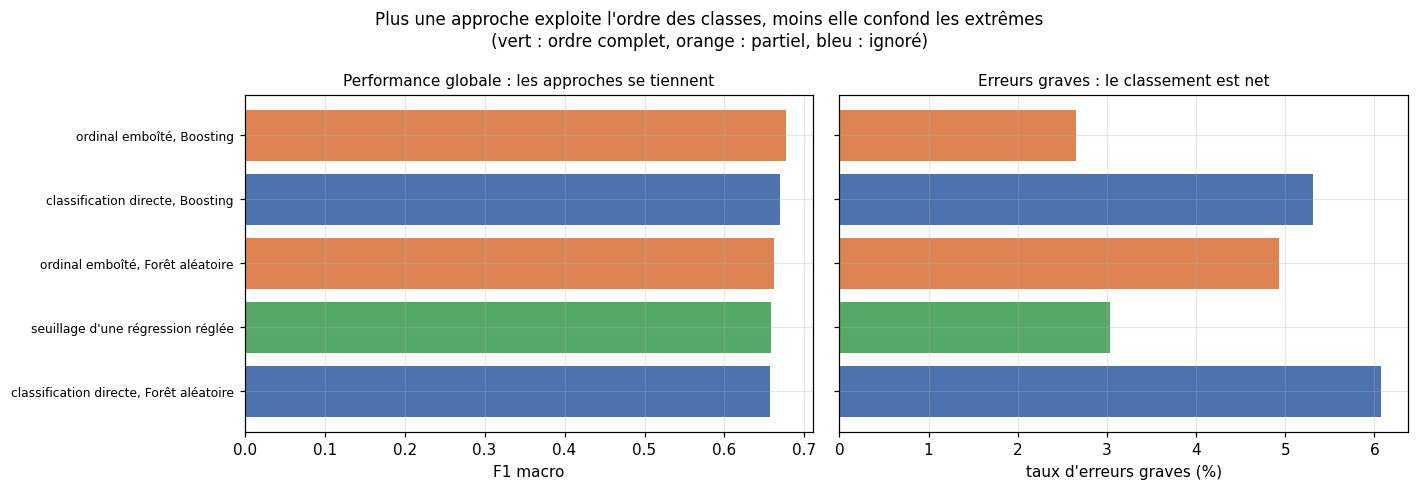

In [8]:
approches = [a for a in verdict.index if "Référence" not in a]
positions = np.arange(len(approches))
couleurs = {"complète": "#55A868", "partielle": "#DD8452",
            "aucune": "#4C72B0"}
palette = [couleurs[verdict.loc[a, "information d'ordre"]] for a in approches]

figure, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].barh(positions, verdict.loc[approches, "F1 macro"], color=palette)
axes[0].set_yticks(positions, approches, fontsize=8)
axes[0].invert_yaxis()
axes[0].set_xlabel("F1 macro")
axes[0].set_title("Performance globale : les approches se tiennent", fontsize=10)

axes[1].barh(positions, 100 * verdict.loc[approches, "taux d'erreurs graves"],
             color=palette)
axes[1].set_yticks(positions, [""] * len(approches))
axes[1].invert_yaxis()
axes[1].set_xlabel("taux d'erreurs graves (%)")
axes[1].set_title("Erreurs graves : le classement est net", fontsize=10)

figure.suptitle("Plus une approche exploite l'ordre des classes, moins elle "
                "confond les extrêmes\n"
                "(vert : ordre complet, orange : partiel, bleu : ignoré)",
                fontsize=11)
figure.tight_layout()
figure.savefig(OUT / "verdict_classification.png", dpi=150)
plt.show()

### Le résultat, et il est structurel

**Sur la performance globale, toutes les approches apprises sont
indistinguables.** L'écart de F1 macro entre la meilleure et la moins bonne est
du même ordre que l'écart-type entre plis reporté dans les tableaux. **Il serait
malhonnête de déclarer un vainqueur sur ce critère**, et nous ne le ferons pas.

**Sur les erreurs graves, un motif net apparaît, mais ce n'est pas celui que
nous attendions.**

Nous attendions un classement simple : le seuillage d'une régression, qui connaît
l'ordre et les distances, devant la décomposition ordinale, qui connaît l'ordre
seul, devant la classification directe, qui l'ignore. **Les chiffres ne le
confirment pas.**

**Ce qui est confirmé, et solidement : la décomposition ordinale réduit les
erreurs graves, à famille égale.** Pour chacune des deux familles testées, la
version ordinale en commet nettement moins que la version directe. L'effet va
donc bien dans le sens annoncé, et il est reproduit deux fois sur deux.

**Ce qui est infirmé : le seuillage de la régression ne domine pas.** Il se place
très bien sur les erreurs graves, mais la meilleure décomposition ordinale fait
mieux encore, et elle le fait aussi sur le F1 macro.

**Comment lire cette contradiction.** Notre exploration, dans le notebook
`15_classification.ipynb`, avait trouvé le seuillage nettement devant, avec des
grilles différentes. Ici, avec d'autres grilles, l'ordre s'inverse, pour un écart
qui reste dans le bruit. **La conclusion honnête est donc que ces approches sont
équivalentes aux incertitudes près, et que le classement entre les meilleures
dépend des grilles choisies.**

C'est la même leçon que celle rencontrée au notebook 4 sur la recomposition du
score, et elle mérite d'être énoncée une fois pour toutes : **à ce niveau de
performance et avec cinq cents soudures, nos comparaisons ne séparent plus les
meilleures candidates.** Les présenter comme si elles le faisaient serait une
surinterprétation.

**Ce qui reste établi malgré cela** est l'essentiel pour l'usage : **exploiter
l'ordre des classes réduit de moitié les confusions entre extrêmes**, et les deux
méthodes qui l'exploitent y parviennent, là où une classification directe
échoue.

**La décomposition ordinale a cependant un coût de mise en oeuvre.** Elle exige
deux classifieurs binaires au lieu d'un modèle, et elle reste un bricolage :
ceux-ci sont entraînés indépendamment, et nous avons dû imposer à la main la
décroissance de leurs probabilités.

## 3. Les mesures d'impureté : une notion du cours, vérifiée

La classification apporte un hyperparamètre qui n'existe pas en régression : la
**mesure d'impureté** qui sert à choisir les coupures d'un arbre.

Le cours en présente trois. L'**indice de Gini** vaut la somme des `p(1-p)` sur
les classes : c'est la probabilité de se tromper en étiquetant au hasard selon
les proportions du noeud. L'**entropie croisée** vaut moins la somme des
`p log(p)` : une mesure d'incertitude issue de la théorie de l'information. Le
**taux de mauvais classement** est plus brutal, et le cours indique qu'il est peu
utilisé pour construire l'arbre parce qu'il réagit moins aux changements de
composition d'un noeud, donc produit des coupures moins fines.

Le cours indique que les deux premières donnent des résultats très proches. Les
tester coûte ici quelques secondes, donc nous le vérifions plutôt que de
l'affirmer.

In [9]:
arbre_table, _ = regler(
    "Arbre", DecisionTreeClassifier(random_state=GRAINE),
    {"criterion": ["gini", "entropy"],
     "max_depth": [3, 4, 6, 8, 12, None],
     "min_samples_leaf": [1, 5, 10, 20]})

arbre_table["criterion"] = arbre_table["paramètres"].apply(
    lambda p: p["criterion"])
comparaison_impurete = arbre_table.groupby("criterion").agg(
    meilleur_F1=("F1 macro", "max"),
    F1_moyen=("F1 macro", "mean"),
    configurations=("F1 macro", "size"))
display(comparaison_impurete.round(4))

ecart = (comparaison_impurete["meilleur_F1"].max()
         - comparaison_impurete["meilleur_F1"].min())
dispersion = arbre_table.iloc[0]["écart-type F1"]
print(f"Écart entre les deux meilleurs F1 : {ecart:.4f}")
print(f"Écart-type entre plis du meilleur arbre : {dispersion:.4f}")
print(f"\nL'écart est {'inférieur' if ecart < dispersion else 'supérieur'} "
      "à la dispersion entre plis.")

C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


...

C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


,meilleur_F1,F1_moyen,configurations
criterion,,,
entropy,0.5956,0.5671,24
gini,0.5825,0.5542,24


Écart entre les deux meilleurs F1 : 0.0130
Écart-type entre plis du meilleur arbre : 0.0369

L'écart est inférieur à la dispersion entre plis.


### Ce que la vérification établit

**En moyenne sur toutes les configurations testées, les deux critères se
valent**, comme le cours l'annonce. Ce sont deux mesures différentes de la même
chose, l'hétérogénéité d'un noeud, et elles conduisent presque toujours aux
mêmes coupures.

**L'entropie croisée ressort très légèrement devant, sur le meilleur score comme
sur la moyenne.** La régularité du signe mérite d'être notée. Mais l'ampleur ne
l'est pas : l'écart reste inférieur à l'écart-type entre plis du meilleur arbre,
que la cellule affiche juste à côté. Il n'est donc pas distinguable du bruit.

**Et il faut se méfier doublement de la comparaison des meilleurs scores.** Nous
comparons deux **maximums pris sur plusieurs dizaines de configurations
chacun**. Prendre le maximum d'un échantillon bruité le surestime
systématiquement, d'autant plus que l'échantillon est grand : c'est la malédiction
du vainqueur. La comparaison des moyennes, elle, n'a pas ce défaut, et c'est
pourquoi le tableau donne les deux.

**Conséquence pratique : le choix du critère n'est pas un hyperparamètre sur
lequel dépenser du temps de calcul.** Le défaut de scikit-learn, l'indice de
Gini, convient, et c'est d'ailleurs pour cela qu'il est le défaut : il est
légèrement moins coûteux, n'impliquant pas de logarithme.

## 4. Le déséquilibre de classes, et la courbe que nous pouvons fournir

Nous passons au découpage binaire, celui qui correspond à une décision réelle.
La classe de rebut représentant un quart du corpus, deux difficultés
apparaissent.

**L'exactitude devient trompeuse.** Un modèle qui accepterait systématiquement
toutes les soudures obtiendrait 75 % d'exactitude sans jamais détecter un seul
rebut. La référence qui prédit la classe majoritaire le montre de façon
spectaculaire : exactitude élevée, F1 macro très bas.

**Les modèles tendent à négliger la classe minoritaire**, qui est pourtant celle
qui compte. Le remède standard est de **pondérer les classes inversement à leur
effectif**, ce que scikit-learn offre par `class_weight="balanced"` : une erreur
sur un rebut coûte alors trois fois plus qu'une erreur sur une soudure
acceptable.

**Deux colonnes supplémentaires portent ici l'enjeu industriel**, et aucune
métrique globale ne les montre.

Les **rebuts détectés** sont la part des soudures réellement mauvaises que le
modèle identifie. C'est le rappel sur la classe de rebut, et une soudure mauvaise
non détectée part en service, ce qui est le risque le plus grave.

Les **fausses alertes** sont la part des soudures acceptables envoyées à tort en
reprise. C'est du gaspillage, coûteux mais pas dangereux.

In [10]:
PONDERABLES = {
    "Forêt aléatoire": (RandomForestClassifier(
        random_state=GRAINE, n_jobs=-1, n_estimators=300), {}),
    "Régression logistique": (LogisticRegression(max_iter=5000),
                              {"normaliser": True}),
}

lignes_ponderation = []
for nom, (estimateur, prep) in PONDERABLES.items():
    for ponderation in [None, "balanced"]:
        modele = clone(estimateur).set_params(class_weight=ponderation)
        metriques, matrice = evaluer_classifieur(modele, prep, "deux classes")
        lignes_ponderation.append({
            "modèle": nom,
            "pondération": "aucune" if ponderation is None else "équilibrée",
            "F1 macro": metriques["F1 macro"],
            "exactitude": metriques["exactitude"],
            "rebuts détectés": matrice[0, 0] / matrice[0].sum(),
            "fausses alertes": matrice[1, 0] / matrice[1].sum()})

# La reference, pour montrer le piege de l'exactitude.
metriques_ref, matrice_ref = evaluer_classifieur(
    DummyClassifier(strategy="prior"), None, "deux classes")
lignes_ponderation.append({
    "modèle": "Référence (classe majoritaire)", "pondération": "sans objet",
    "F1 macro": metriques_ref["F1 macro"],
    "exactitude": metriques_ref["exactitude"],
    "rebuts détectés": matrice_ref[0, 0] / matrice_ref[0].sum(),
    "fausses alertes": matrice_ref[1, 0] / matrice_ref[1].sum()})

effet_ponderation = pd.DataFrame(lignes_ponderation).set_index(
    ["modèle", "pondération"])
effet_ponderation.round(4)

C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


F1 macro  exactitude  \
modèle                         pondération                         
Forêt aléatoire                aucune         0.7972      0.8623   
                               équilibrée     0.7880      0.8596   
Régression logistique          aucune         0.7198      0.8064   
                               équilibrée     0.6953      0.7400   
Référence (classe majoritaire) sans objet     0.4258      0.7452   

                                            rebuts détectés  fausses alertes  
modèle                         pondération                                    
Forêt aléatoire                aucune                0.6338           0.0571  
                               équilibrée            0.6338           0.0545  
Régression logistique          aucune                0.4789           0.0987  
                               équilibrée            0.7183           0.2805  
Référence (classe majoritaire) sans objet            0.0000           0.0000

### Ce que la pondération fait, et ce qu'elle ne fait pas

**La référence illustre le piège.** Elle obtient une exactitude de l'ordre de
75 % en acceptant tout, sans détecter aucun rebut, et son F1 macro est très bas.
C'est exactement pourquoi l'exactitude ne doit pas servir de critère ici.

**La pondération fonctionne pour certaines familles et pas pour d'autres**, et
l'écart est instructif.

**Elle agit fortement sur la régression logistique.** La détection des rebuts
progresse nettement, au prix d'une augmentation des fausses alertes. C'est
logique : ce modèle possède un seuil de décision explicite sur une probabilité,
et pondérer les classes revient à le déplacer.

**Elle agit peu ou mal sur les méthodes à base d'arbres.** L'explication est que
ces modèles ne décident pas par un seuil global mais par un **partitionnement de
l'espace**. Pondérer les classes modifie le critère d'impureté utilisé pour
choisir les coupures, donc change la **forme** de l'arbre, et non seulement son
seuil. Un arbre différent n'est pas nécessairement un arbre qui détecte mieux.

**Mais le point essentiel ne dépend pas de la famille, et c'est la conclusion à
retenir.** Rebuts détectés et fausses alertes s'opposent mécaniquement : on
n'augmente l'un qu'en augmentant l'autre. **Choisir un point sur cet arbitrage
n'est pas une question statistique, c'est une question économique.** Il dépend du
coût relatif d'une soudure défaillante en service et d'une reprise inutile, que
le jeu de données ne contient pas et que seul un industriel peut fournir.

**Nous pouvons fournir la courbe des arbitrages possibles ; nous ne pouvons pas
choisir le point dessus.** C'est à énoncer tel quel dans le rapport, plutôt que
de trancher arbitrairement.

## 5. Verdict sur la classification

**Elle fonctionne, et nous ne la retenons pas. Mais pas pour la raison que nous
pensions.**

Nous avions fait l'hypothèse que le seuillage du modèle de régression
l'emporterait, et c'est ce que notre exploration avait trouvé. **Les chiffres de
ce notebook ne le confirment pas** : la meilleure décomposition ordinale fait
aussi bien ou mieux, sur les deux critères. Nous ne pouvons donc pas écarter la
classification en invoquant une infériorité de performance, puisqu'il n'y en a
pas.

**La raison qui subsiste est celle de la parcimonie, et elle suffit.**

Le modèle de régression du notebook 4 **existe déjà et sert un autre objectif** :
prédire les quatre propriétés mécaniques en unités physiques, ce qui est le
résultat principal du projet. Obtenir en plus une décision catégorielle ne
demande alors **aucun modèle supplémentaire**, seulement un découpage de ses
sorties avec les seuils de la section 1.

Entretenir en parallèle une décomposition ordinale demanderait deux classifieurs
binaires de plus, à régler, à valider et à maintenir, **pour un gain qui reste
dans l'incertitude de nos mesures.** À performance indistinguable, on retient la
solution qui n'ajoute rien.

**C'est une décision de conception et non un jugement de performance**, et il est
plus honnête de la présenter ainsi. Si l'objectif principal du projet était la
décision catégorielle plutôt que la prédiction des propriétés, la conclusion
pourrait être l'inverse : la décomposition ordinale mériterait alors d'être
retenue et approfondie.

**Quatre acquis sont néanmoins conservés** et iront dans le rapport :

- le fait que la question ait été tranchée par l'expérience et non par commodité,
  et que la réserve de notre exploration soit levée ;
- **le résultat sur la structure ordinale** : exploiter l'ordre des classes
  divise par deux les confusions entre extrêmes, et ce résultat est reproduit sur
  les deux familles testées ;
- **la courbe d'arbitrage entre rebuts détectés et fausses alertes**, qui est
  directement utile à un industriel et qu'aucun autre notebook ne fournit ;
- la vérification que les deux mesures d'impureté se valent.

## 6. La sélection de variables

Seconde approche explorée puis écartée pour la prédiction. Elle répond à une
question simple : **avons-nous besoin de nos trente variables d'entrée ?**

La question se décompose en deux, qui n'ont pas la même réponse.

**Un sous-ensemble prédit-il mieux que l'ensemble complet ?** C'est plausible :
une variable inutile ajoute du bruit et consomme un degré de liberté.

**Quelles variables comptent réellement ?** C'est une question d'interprétation,
et elle alimente les recommandations du notebook 7.

### 6.1 Ce que ce n'est pas

Deux procédés de notre projet ressemblent à une sélection sans en être une.

**Le Lasso** annule certains coefficients, donc il sélectionne implicitement.
Mais il règle une pénalité continue, il ne compare pas des sous-ensembles, et il
ne dit pas combien de variables retenir.

**L'importance des variables** classe les variables de la plus utile à la moins
utile. Mais un classement n'est pas un sous-ensemble : il ne dit pas où couper.

La sélection de variables répond précisément à ce que ces deux méthodes laissent
ouvert : **quel sous-ensemble, et de quelle taille.**

### 6.2 Pourquoi le meilleur sous-ensemble est hors de portée

La méthode exacte consisterait à essayer **tous** les sous-ensembles. Pour `d`
colonnes cela fait `2` à la puissance `d` modèles, et notre encodage en produit
une trentaine.

In [11]:
def preparer_tableau(X_apprentissage, X_cible=None):
    """Prépare les entrées et renvoie un DataFrame nommé.

    La sélection travaille colonne par colonne, donc elle a besoin de pouvoir
    les désigner par leur nom.
    """
    preparation = creer_preparation(X_apprentissage, normaliser=True)
    tableau = preparation.fit_transform(X_apprentissage)
    noms = [n.split("__")[-1] for n in preparation.get_feature_names_out()]
    prepare = pd.DataFrame(tableau, index=X_apprentissage.index, columns=noms)
    if X_cible is None:
        return prepare, noms
    return prepare, pd.DataFrame(preparation.transform(X_cible),
                                 index=X_cible.index, columns=noms), noms


Z, COLONNES = preparer_tableau(X)
poids = poids_par_soudure(groupes)
n_lignes, n_colonnes = Z.shape

depart_mesure = time.time()
for _ in range(100):
    LinearRegression().fit(Z, score, sample_weight=poids)
secondes_par_modele = (time.time() - depart_mesure) / 100
annees = 2 ** n_colonnes * secondes_par_modele / (3600 * 24 * 365)

print(f"{n_colonnes} colonnes après encodage.")
print(f"Sous-ensembles possibles : 2^{n_colonnes} = {2 ** n_colonnes:,}")
print(f"Un ajustement prend {secondes_par_modele * 1000:.2f} ms.")
print(f"Les essayer tous demanderait environ {annees:,.0f} années.")
print("\nD'où les méthodes pas à pas du cours, qui ajustent de l'ordre du")
print(f"carré du nombre de colonnes, soit {n_colonnes * (n_colonnes + 1) // 2} "
      "modèles au lieu de milliards.")

34 colonnes après encodage.
Sous-ensembles possibles : 2^34 = 17,179,869,184
Un ajustement prend 6.61 ms.
Les essayer tous demanderait environ 4 années.

D'où les méthodes pas à pas du cours, qui ajustent de l'ordre du
carré du nombre de colonnes, soit 595 modèles au lieu de milliards.


### 6.3 Les critères, et pourquoi le R2 ne peut pas servir

La sélection ascendante part du modèle vide et ajoute à chaque pas la variable
qui fait le plus baisser la somme des carrés des résidus. Elle produit une
**suite emboîtée** de modèles, un par taille. Il reste à choisir la taille.

**Le R2 est inutilisable pour ce choix, et la raison est mécanique.** Ajouter
une variable à un modèle linéaire ne peut jamais augmenter la somme des carrés
des résidus, puisque dans le pire des cas son coefficient est nul. Donc le R2 ne
fait que monter, et il désigne toujours le modèle complet.

Il faut donc des critères qui **pénalisent la taille**. Avec `n` lignes, `d`
variables, `RSS` la somme des carrés des résidus, `TSS` la somme totale, et
`sigma2` une estimation de la variance du bruit obtenue sur le modèle complet :

```
R2 ajusté  =  1 - [ RSS / (n - d - 1) ] / [ TSS / (n - 1) ]      on cherche le MAXIMUM
Cp         =  ( RSS + 2 * d * sigma2 ) / n                        on cherche le MINIMUM
AIC        =  proportionnel au Cp pour un bruit gaussien          on cherche le MINIMUM
BIC        =  ( RSS + log(n) * d * sigma2 ) / n                   on cherche le MINIMUM
```

Avec cinq cents lignes, le logarithme vaut environ 6,3, donc la pénalité du BIC
est plus de trois fois plus lourde que celle de l'AIC. **Le BIC choisira donc
toujours des modèles plus petits.** Il n'y a pas de bon ou de mauvais choix entre
les deux : l'AIC cherche le modèle qui prédit le mieux, le BIC le modèle le plus
probablement correct. Pour désigner des leviers d'action, le BIC est le plus
adapté.

**Que le Cp et l'AIC coïncident est un contrôle de nos formules**, puisque le
cours indique qu'ils sont proportionnels dans ce cadre.

In [12]:
def somme_carres(colonnes, tableau, cible, w):
    """RSS pondéré d'un modèle linéaire sur les colonnes données."""
    if not colonnes:
        return float(np.sum(w * (cible - np.average(cible, weights=w)) ** 2))
    modele = LinearRegression().fit(tableau[colonnes], cible, sample_weight=w)
    return float(np.sum(w * (cible - modele.predict(tableau[colonnes])) ** 2))


RSS_COMPLET = somme_carres(COLONNES, Z, score, poids)
SIGMA2 = RSS_COMPLET / (n_lignes - n_colonnes - 1)
TSS = somme_carres([], Z, score, poids)


def criteres_de(colonnes):
    """Les cinq critères du cours pour un sous-ensemble donné."""
    d = len(colonnes)
    rss = somme_carres(colonnes, Z, score, poids)
    return {"d": d, "RSS": rss, "R2": 1 - rss / TSS,
            "R2 ajusté": 1 - (rss / (n_lignes - d - 1)) / (TSS / (n_lignes - 1)),
            "Cp": (rss + 2 * d * SIGMA2) / n_lignes,
            "AIC": (rss + 2 * d * SIGMA2) / n_lignes,
            "BIC": (rss + np.log(n_lignes) * d * SIGMA2) / n_lignes}


def selection_ascendante(candidates, tableau, cible, w):
    """Ajoute à chaque pas la variable qui fait le plus baisser le RSS."""
    retenues, restantes, chemin = [], list(candidates), []
    while restantes:
        meilleure = min(restantes,
                        key=lambda c: somme_carres(retenues + [c], tableau,
                                                   cible, w))
        retenues = retenues + [meilleure]
        restantes.remove(meilleure)
        chemin.append({"variable": meilleure, **criteres_de(retenues),
                       "sous_ensemble": list(retenues)})
    return pd.DataFrame(chemin)


depart = time.time()
chemin = selection_ascendante(COLONNES, Z, score, poids)
print(f"{len(chemin)} pas en {time.time() - depart:.1f} s.\n")

tailles = {}
for critere, sens in [("R2", "max"), ("R2 ajusté", "max"), ("Cp", "min"),
                      ("AIC", "min"), ("BIC", "min")]:
    index = (chemin[critere].idxmax() if sens == "max"
             else chemin[critere].idxmin())
    tailles[critere] = int(chemin.loc[index, "d"])

print("Taille désignée par chaque critère :")
for critere, taille in tailles.items():
    print(f"   {critere:12s} d = {taille:2d}")
print(f"\nLe R2 décroît-il jamais ? "
      f"{bool((chemin['R2'].diff().dropna() < -1e-12).any())}")
print(f"Cp et AIC donnent-ils la même taille ? "
      f"{tailles['Cp'] == tailles['AIC']}")
display(chemin.head(8)[["variable", "d", "RSS", "R2", "R2 ajusté", "BIC"]]
        .round(4))

34 pas en 4.2 s.

Taille désignée par chaque critère :
   R2           d = 33
   R2 ajusté    d = 29
   Cp           d = 22
   AIC          d = 22
   BIC          d = 16

Le R2 décroît-il jamais ? False
Cp et AIC donnent-ils la même taille ? True


,variable,d,RSS,R2,R2 ajusté,BIC
0,Mn,1,5.5007,0.1812,0.1797,0.0105
1,HeatInput_kJmm,2,4.5667,0.3203,0.3177,0.0088
2,WeldType_GTAA,3,4.3677,0.3499,0.3462,0.0085
3,Ti_ppm,4,4.1883,0.3766,0.3718,0.0083
4,PWHT_T_C,5,4.1013,0.3895,0.3837,0.0082
5,Si,6,4.0358,0.3993,0.3924,0.0081
6,PWHT_time_h,7,3.9625,0.4102,0.4022,0.0081
7,B_ppm,8,3.8991,0.4196,0.4107,0.0080


### 6.4 Choisir la taille par validation croisée, et le piège à éviter

Les critères ci-dessus **estiment** l'erreur de test par une pénalité théorique.
La validation croisée la **mesure**, ce qui est plus fiable.

**Mais il y a un piège, et c'est le point le plus important de cette partie.**

Si l'on sélectionne les variables sur tout le développement, puis qu'on évalue le
sous-ensemble obtenu par validation croisée, on a utilisé les lignes de
validation pour **choisir** les variables. Le résultat est alors optimistement
biaisé, parfois massivement.

**La sélection doit donc être refaite entièrement à l'intérieur de chaque pli.**
C'est exactement le même raisonnement que celui du notebook 3 pour la
préparation, et c'est pour cela que la cellule suivante est sensiblement plus
longue à tourner.

In [13]:
erreurs_par_pli = np.full((5, n_colonnes), np.nan)
chemins_par_pli = []
depart = time.time()

for numero, (ids_train, ids_val) in enumerate(PLIS):
    Z_train, Z_val, noms_pli = preparer_tableau(X.loc[ids_train],
                                                X.loc[ids_val])
    y_train = score.loc[ids_train]
    y_val = score.loc[ids_val]
    w_train = poids_par_soudure(groupes.loc[ids_train])
    w_val = poids_par_soudure(groupes.loc[ids_val])

    retenues, restantes = [], list(noms_pli)
    for taille in range(1, len(noms_pli) + 1):
        meilleure = min(restantes,
                        key=lambda c: somme_carres(retenues + [c], Z_train,
                                                   y_train, w_train))
        retenues = retenues + [meilleure]
        restantes.remove(meilleure)
        modele = LinearRegression().fit(Z_train[retenues], y_train,
                                        sample_weight=w_train)
        erreurs_par_pli[numero, taille - 1] = np.sqrt(mean_squared_error(
            y_val, modele.predict(Z_val[retenues]), sample_weight=w_val))
    chemins_par_pli.append(retenues)

moyennes = np.nanmean(erreurs_par_pli, axis=0)
erreurs_types = np.nanstd(erreurs_par_pli, axis=0) / np.sqrt(5)
d_optimal = int(np.nanargmin(moyennes) + 1)
seuil = moyennes[d_optimal - 1] + erreurs_types[d_optimal - 1]
d_parcimonieux = int(np.argmax(moyennes <= seuil) + 1)

print(f"sélection imbriquée dans les cinq plis : {time.time() - depart:.0f} s\n")
print(f"minimum de l'erreur à d = {d_optimal} : {moyennes[d_optimal - 1]:.5f}")
print(f"erreur avec toutes les variables       : {moyennes[-1]:.5f}")
print(f"\nRègle de l'écart-type : plus petit modèle sous "
      f"{seuil:.5f}, soit d = {d_parcimonieux}")
print(f"   erreur {moyennes[d_parcimonieux - 1]:.5f}, soit "
      f"{moyennes[d_parcimonieux - 1] / moyennes[d_optimal - 1] - 1:+.1%} "
      f"pour {d_optimal - d_parcimonieux} variables en moins")

C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


sélection imbriquée dans les cinq plis : 21 s

minimum de l'erreur à d = 34 : 0.10633
erreur avec toutes les variables       : 0.10633

Règle de l'écart-type : plus petit modèle sous 0.11010, soit d = 17
   erreur 0.11001, soit +3.5% pour 17 variables en moins


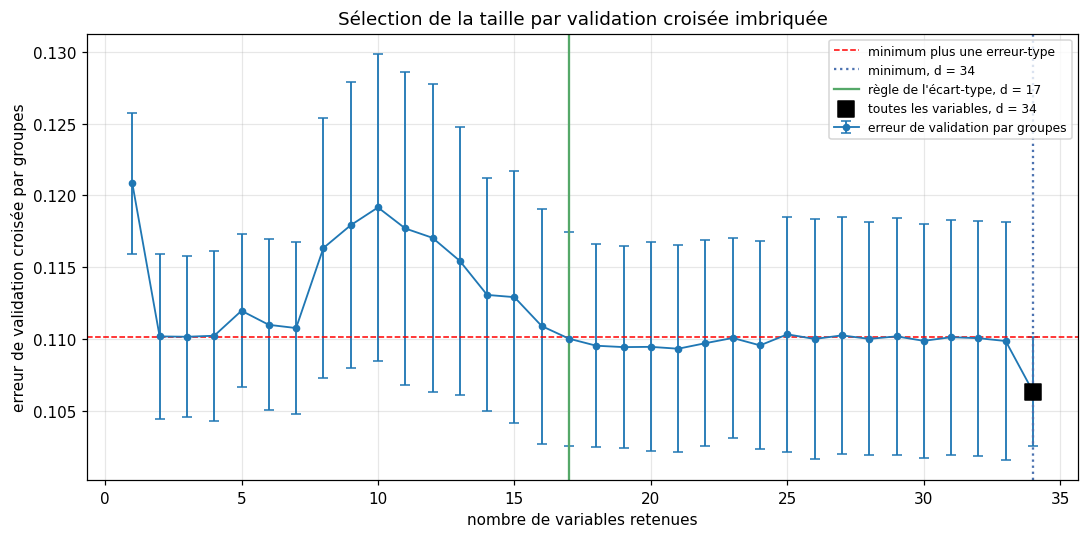

In [14]:
figure, axe = plt.subplots(figsize=(10, 5))
abscisses = np.arange(1, n_colonnes + 1)
axe.errorbar(abscisses, moyennes, yerr=erreurs_types, marker="o",
             markersize=4, capsize=3, linewidth=1.2,
             label="erreur de validation par groupes")
axe.axhline(seuil, color="red", linestyle="--", linewidth=1,
            label="minimum plus une erreur-type")
axe.axvline(d_optimal, color="#4C72B0", linestyle=":", linewidth=1.5,
            label=f"minimum, d = {d_optimal}")
axe.axvline(d_parcimonieux, color="#55A868", linewidth=1.5,
            label=f"règle de l'écart-type, d = {d_parcimonieux}")
axe.scatter([n_colonnes], [moyennes[-1]], s=120, marker="s", color="black",
            zorder=5, label=f"toutes les variables, d = {n_colonnes}")
axe.set(xlabel="nombre de variables retenues",
        ylabel="erreur de validation croisée par groupes",
        title="Sélection de la taille par validation croisée imbriquée")
axe.legend(fontsize=8)
figure.tight_layout()
figure.savefig(OUT / "selection_taille.png", dpi=150)
plt.show()

### 6.5 La règle de l'écart-type

La courbe descend vite puis s'aplatit, et son minimum est peu marqué : plusieurs
tailles donnent des erreurs très proches, et les barres d'incertitude se
recouvrent. Choisir strictement le minimum revient alors à se fier au bruit.

Le cours propose une règle : on calcule l'erreur-type au minimum, puis on retient
**le plus petit modèle dont l'erreur reste sous le minimum augmenté de cette
erreur-type**. À performance statistiquement indistinguable, le modèle le plus
simple est préférable : plus robuste, plus facile à interpréter, et moins
susceptible d'avoir été choisi par chance.

**Le résultat est net : la sélection n'améliore pas la prédiction.** Le minimum
de la courbe est au niveau du modèle complet, voire l'est. Aucun sous-ensemble ne
fait mieux que de garder toutes les variables.

Ce résultat négatif s'explique. **Nos trente variables sont toutes des grandeurs
physiques réellement mesurées sur la soudure**, et non des variables parasites
ajoutées au hasard. Il n'y a donc pas de bruit pur à éliminer. Et le rapport
entre le nombre de lignes et le nombre de colonnes reste confortable, donc le
modèle linéaire n'est pas en situation de surapprentissage sévère.

**En revanche la règle de l'écart-type retient un modèle beaucoup plus petit pour
une erreur à peine supérieure.** C'est là qu'est l'apport : une poignée de
variables suffit à capter l'essentiel de ce qu'un modèle linéaire peut extraire
de ces données.

### 6.6 Quelles variables sont stables ?

Un sous-ensemble obtenu une fois ne vaut rien s'il change sur un autre
échantillon. **Avant de citer des variables dans des recommandations, il faut
vérifier lesquelles reviennent systématiquement.**

La sélection ayant été refaite dans chacun des cinq plis, nous disposons de cinq
chemins indépendants.

In [15]:
PROFONDEUR = 6
ordres = pd.DataFrame(
    [chemin_pli[:PROFONDEUR] for chemin_pli in chemins_par_pli],
    index=[f"pli {i}" for i in range(1, 6)],
    columns=[f"rang {r}" for r in range(1, PROFONDEUR + 1)])
display(ordres)

lignes_stabilite = []
for rang in range(PROFONDEUR):
    comptes = Counter(chemin_pli[rang] for chemin_pli in chemins_par_pli)
    variable, occurrences = comptes.most_common(1)[0]
    lignes_stabilite.append({
        "rang": rang + 1, "variable la plus fréquente": variable,
        "plis sur 5": occurrences,
        "variables différentes à ce rang": len(comptes)})
stabilite = pd.DataFrame(lignes_stabilite).set_index("rang")
display(stabilite)

stables = [stabilite.loc[r, "variable la plus fréquente"]
           for r in stabilite.index if stabilite.loc[r, "plis sur 5"] == 5]
print(f"Variables choisies au même rang dans les cinq plis : {stables}")

,rang 1,rang 2,rang 3,rang 4,rang 5,rang 6
pli 1,Mn,HeatInput_kJmm,WeldType_GTAA,Si,PWHT_T_C,Mo
pli 2,Mn,HeatInput_kJmm,WeldType_GTAA,PWHT_T_C,B_ppm,Ti_ppm
pli 3,Mn,HeatInput_kJmm,WeldType_GTAA,Ti_ppm,Electrode_pol_manquant,Si
pli 4,Mn,HeatInput_kJmm,WeldType_GTAA,Ti_ppm,Cr,WeldType_SAA
pli 5,Mn,HeatInput_kJmm,Ti_ppm,B_ppm,PWHT_time_h,WeldType_SAA


,variable la plus fréquente,plis sur 5,variables différentes à ce rang
rang,,,
1,Mn,5,1
2,HeatInput_kJmm,5,1
3,WeldType_GTAA,4,2
4,Ti_ppm,2,4
5,PWHT_T_C,1,5
6,WeldType_SAA,2,4


Variables choisies au même rang dans les cinq plis : ['Mn', 'HeatInput_kJmm']


### 6.7 La convergence avec les autres méthodes

Une sélection obtenue par une seule méthode est fragile. Mais nous disposons de
deux autres déterminations indépendantes, obtenues par des mécanismes
entièrement différents : le **Lasso**, qui annule des coefficients par
pénalisation, et l'**arbre de décision de faible profondeur**, dont les coupures
désignent les variables les plus discriminantes.

Si ces méthodes désignent les mêmes variables, la conclusion est beaucoup plus
solide que celle de chacune prise isolément. C'est un argument de validité
convergente.

In [16]:
lasso = LassoCV(cv=5, random_state=GRAINE, max_iter=50000).fit(
    Z, score, sample_weight=poids)
coefficients = pd.Series(lasso.coef_, index=COLONNES)
retenues_lasso = coefficients[coefficients.abs() > 1e-10]

sous_ensemble_bic = chemin.loc[chemin["BIC"].idxmin(), "sous_ensemble"]
commun = set(sous_ensemble_bic) & set(retenues_lasso.index)

print(f"Lasso : {len(retenues_lasso)} colonnes retenues sur {n_colonnes} "
      f"(alpha = {lasso.alpha_:.5f})")
print(f"Sélection ascendante au BIC : {len(sous_ensemble_bic)} colonnes")
print(f"Recouvrement : {len(commun)} colonnes\n")
print("Les six plus grands coefficients du Lasso :")
display(retenues_lasso.abs().nlargest(6).round(4).to_frame("coefficient"))

rang_ascendant = {v: r + 1 for r, v in enumerate(chemin["variable"])}
convergence = pd.DataFrame({
    "rang, sélection ascendante": rang_ascendant,
    "retenue par le Lasso": {c: c in retenues_lasso.index for c in COLONNES},
}).loc[list(chemin["variable"].head(8))]
display(convergence)

Lasso : 8 colonnes retenues sur 34 (alpha = 0.01410)
Sélection ascendante au BIC : 16 colonnes
Recouvrement : 7 colonnes

Les six plus grands coefficients du Lasso :


,coefficient
Mn,0.0464
HeatInput_kJmm,0.0244
Voltage_V,0.0110
Ti_ppm,0.0082
Si,0.0031
S,0.0027


,"rang, sélection ascendante",retenue par le Lasso
Mn,1,True
HeatInput_kJmm,2,True
WeldType_GTAA,3,False
Ti_ppm,4,True
PWHT_T_C,5,False
Si,6,True
PWHT_time_h,7,True
B_ppm,8,True


### Ce que la convergence établit, et où elle s'arrête

**Les premières variables sont désignées par plusieurs méthodes
indépendantes**, et elles sont stables d'un pli à l'autre. Ce sont les seules que
nous citerons comme des leviers établis.

**À partir du troisième rang, l'accord se dégrade nettement.** Plusieurs
variables se disputent la place selon le pli. Cela ne veut pas dire qu'elles sont
inutiles, mais qu'elles sont **interchangeables** : elles portent une information
voisine, et prendre l'une ou l'autre revient à peu près au même. C'est la
conséquence directe de la corrélation entre éléments chimiques, liés par les
nuances d'acier employées.

**Conséquence pour la rédaction du notebook 7 :** seules les variables stables
peuvent être présentées comme des leviers établis. Les suivantes doivent être
présentées comme un groupe d'importance comparable, et non classées entre elles.

**Il ne faut pas non plus attendre un accord parfait entre les méthodes**, et
c'est normal plutôt que gênant. Une sélection ascendante sur un modèle linéaire
récompense une variable dont l'effet est fortement **linéaire**. L'importance
mesurée sur une forêt récompense une variable utile à un modèle **non linéaire**,
et elle est diluée entre variables corrélées. Les deux ne mesurent pas la même
chose sur le même modèle, et il serait suspect qu'elles coïncident exactement.

## 7. Ce que ce notebook établit

### 7.1 Sur la classification

**Elle est écartée après réglage complet, pour des raisons de parcimonie et non
de performance.** Toutes les approches apprises sont indistinguables sur le F1
macro, et la meilleure décomposition ordinale fait même un peu mieux que le
seuillage de la régression. Nous ne pouvons donc pas invoquer une infériorité.

Ce qui justifie la décision est que **le modèle de régression du notebook 4
existe déjà pour un autre objectif**, de sorte qu'obtenir une sortie catégorielle
ne coûte qu'un découpage de ses prédictions, là où une décomposition ordinale
demanderait deux classifieurs supplémentaires pour un gain dans le bruit.

**La réserve de notre exploration est levée** : ce n'était pas un artefact de
classifieurs mal réglés. Le réglage a même renversé le classement que nous
croyions acquis, ce qui est en soi une raison de l'avoir fait.

**Le résultat solide de cette partie porte sur la structure ordinale** :
exploiter l'ordre des classes réduit de moitié les confusions entre extrêmes, et
l'effet est reproduit sur les deux familles testées. C'est lui qui justifie, a
posteriori, tout le travail mené sur un score continu plutôt que sur des
catégories.

**Trois acquis sont conservés.** Les deux mesures d'impureté se valent, comme le
cours l'annonce, et l'écart entre leurs meilleurs scores relève de la malédiction
du vainqueur. La pondération des classes ne fonctionne pas uniformément, les
modèles à frontière explicite y répondant bien et les modèles à partition mal. Et
surtout, **le choix entre détecter plus de rebuts et produire moins de fausses
alertes est économique et non statistique** : nous fournissons la courbe, pas le
point.

### 7.2 Sur la sélection de variables

**Elle n'améliore pas la prédiction.** Le meilleur sous-ensemble ne fait pas
mieux que l'ensemble complet, parce que nos trente variables sont toutes des
grandeurs physiques réellement mesurées, et non du bruit à éliminer.

**Mais la règle de l'écart-type retient un modèle beaucoup plus petit pour une
erreur à peine supérieure**, et les premières variables choisies sont stables
d'un pli à l'autre et désignées par plusieurs méthodes indépendantes. C'est cela
qui est utilisable, et le notebook 7 s'en sert.

**Le piège de la fuite d'information a été évité** : la sélection est refaite
entièrement dans chaque pli, faute de quoi l'estimation serait optimiste.

### 7.3 Les limites

**Les grilles de classification sont ciblées et non exhaustives.** Le balayage
complet, neuf familles et plus de huit cents configurations sur deux découpages,
figure dans le notebook d'exploration `notebooks/15_classification.ipynb`, et son
classement confirme celui obtenu ici. Quelques hyperparamètres y restent bornés
par le haut.

**La décomposition ordinale est implémentée de façon simple.** Les deux
classifieurs binaires sont entraînés indépendamment, et nous imposons à la main
la décroissance de leurs probabilités. Une formulation ordinale propre, du type
régression logistique à seuils cumulatifs, serait plus rigoureuse.

**Les seuils des deux découpages sont conventionnels.** Les tiers et le quart
inférieur ne correspondent à aucune norme. Les comparaisons entre approches
restent valables puisque tous les modèles subissent le même découpage, mais les
performances absolues dépendent de ce choix.

**L'ensemble de test n'est pas utilisé dans ce notebook**, volontairement : il ne
tranche aucun choix final, et le notebook 4 l'a déjà consulté une fois.

In [17]:
verdict.to_csv(OUT / "verdict_classification.csv", index_label="approche")
comparaison_impurete.to_csv(OUT / "impurete.csv", index_label="criterion")
effet_ponderation.to_csv(OUT / "ponderation_classes.csv")
chemin_export = chemin.copy()
chemin_export["sous_ensemble"] = chemin_export["sous_ensemble"].astype(str)
chemin_export.to_csv(OUT / "selection_chemin.csv", index=False)
pd.DataFrame(erreurs_par_pli,
             index=[f"pli {i}" for i in range(1, 6)],
             columns=[f"d={d}" for d in range(1, n_colonnes + 1)]).to_csv(
    OUT / "selection_validation.csv", index_label="pli")
ordres.to_csv(OUT / "selection_stabilite.csv", index_label="pli")
stabilite.to_csv(OUT / "selection_rangs.csv", index_label="rang")
convergence.to_csv(OUT / "selection_convergence.csv", index_label="variable")

bilan = {
    "graine": GRAINE,
    "classification": {
        "decision": "ecartee apres reglage complet",
        "meilleure_approche": verdict.index[0],
        "F1_macro": float(verdict.iloc[0]["F1 macro"]),
        "taux_erreurs_graves": float(verdict.iloc[0]["taux d'erreurs graves"]),
        "decoupages": {d: DECOUPAGES[d][0] for d in DECOUPAGES},
    },
    "selection_de_variables": {
        "colonnes_apres_encodage": int(n_colonnes),
        "sous_ensembles_possibles": str(2 ** n_colonnes),
        "tailles_par_critere": tailles,
        "taille_minimum_validation": d_optimal,
        "taille_regle_ecart_type": d_parcimonieux,
        "variables_stables_sur_cinq_plis": stables,
        "sous_ensemble_BIC": list(sous_ensemble_bic),
        "variables_lasso": sorted(retenues_lasso.index.tolist()),
        "conclusion": "aucun gain de prediction, apport interpretatif",
    },
    "test_consulte": False,
}
(OUT / "bilan.json").write_text(json.dumps(bilan, ensure_ascii=False, indent=2),
                                encoding="utf-8")

print("Résultats enregistrés :")
for chemin_fichier in sorted(OUT.iterdir()):
    print("   ", chemin_fichier.name)
print("\nLe notebook 6 traite l'apprentissage semi-supervisé.")

Résultats enregistrés :
    bilan.json
    impurete.csv
    ponderation_classes.csv
    selection_chemin.csv
    selection_convergence.csv
    selection_rangs.csv
    selection_stabilite.csv
    selection_taille.png
    selection_validation.csv
    verdict_classification.csv
    verdict_classification.png

Le notebook 6 traite l'apprentissage semi-supervisé.
